SLEEP DISORDER ANALYSIS - EASY VERSION (UPDATED)
================================================================
GOAL:
We want to understand the sleep dataset like a story.
Every important step has:
1. WHY  -> why are we doing it?
2. CODE -> what are we doing?
3. INSIGHT -> what did we learn?
No Machine Learning is used.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Set plot style for better visuals
plt.style.use('seaborn-v0_8')
%matplotlib inline


In [11]:
df = pd.read_csv(
    r"C:\Users\GANESH SINGH\Documents\Codex\2026-09-14\create-an-image-of\work\source\Beginner - Sleep Disorder Analysis\Sleep_disorder_data.csv")

- -----
## STEP 1: READ THE DATA

WHY:
- First, we need to bring the CSV file into Python.
- "*None*" means "no sleep disorder" in this dataset.
- So we tell pandas not to treat "None" as missing data

In [17]:
df = pd.read_csv(
    r"C:\Users\GANESH SINGH\Documents\Codex\2026-09-14\create-an-image-of\work\source\Beginner - Sleep Disorder Analysis\Sleep_disorder_data.csv",keep_default_na=False)

print("Rows and columns:", df.shape)
print()
print(df["Sleep Disorder"].value_counts())


Rows and columns: (374, 13)

Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


**INSIGHT** : The dataset has 374 rows and 13 columns."None" is the biggest sleep-disorder category.

- -----
## STEP 2: CHECK FOR MISSING VALUES

**WHY** : Missing information can give us wrong results.So first we check whether anything is empty.

- -----
## STEP 2: CHECK FOR MISSING VALUES

**WHY** : Missing information can give us wrong results.So first we check whether anything is empty.

In [18]:
print("\nSTEP 2 - MISSING VALUES")
print(df.isna().sum().sort_values(ascending = False).head())


STEP 2 - MISSING VALUES
Person ID         0
Gender            0
Age               0
Occupation        0
Sleep Duration    0
dtype: int64


**INSIGHT** : We can see how many empty values are present in every column. In this dataset, the check shows 0 missing values.

- -----
## STEP 3: CHECK REPEATED RECORDS

**WHY** :
- Imagine writing the same person's information many times.
- That person could then affect our result too much.
- Person ID is ignored because it is only an ID number.
- We check whether the rest of the information is repeated.

In [5]:
same_rows = df.drop(columns="Person ID").duplicated().sum()
print("\nSTEP 3 - REPEATED RECORDS")
print("Repeated records:", same_rows)

NameError: name 'df' is not defined

**INSIGHT** : 242 repeated records were found. This means we should be careful when calculating final results.

- -----
## STEP 4: FIX SIMPLE NAME PROBLEMS

**WHY** :
- "Normal" and "Normal Weight" mean the same thing here.
- Also, "Sales Representative" and "Salesperson" are the same job.
- If we keep two names for the same thing,
- Python will count them as two different groups.

In [37]:
df["BMI Category"] = df["BMI Category"].replace("Normal Weight", "Normal")
df["Occupation"] = df["Occupation"].replace("Sales Representative", "Salesperson")

print(df["BMI Category"].value_counts())
print()
print(df["Occupation"].value_counts())

BMI Category
Normal        216
Overweight    148
Obese          10
Name: count, dtype: int64

Occupation
Nurse                73
Doctor               71
Engineer             63
Lawyer               47
Teacher              40
Accountant           37
Salesperson          34
Software Engineer     4
Scientist             4
Manager               1
Name: count, dtype: int64


**INSIGHT** : We now have one name for each matching category. This makes our group comparisons cleaner.


- -----
## STEP 5: CHANGE BLOOD PRESSURE INTO NUMBERS

**WHY** :
- Blood pressure is written like "126/83".
- Python sees this as text.
- We split it into:
- Higher_BP = 126 (Systolic)
- Lower_BP  = 83  (Diastolic)
- Now Python can calculate averages and compare groups.

In [38]:
bp = df["Blood Pressure"].astype(str).str.split("/", expand=True)
df["Higher_BP"] = pd.to_numeric(bp[0], errors="coerce")
df["Lower_BP"] = pd.to_numeric(bp[1], errors="coerce")


print(df[["Blood Pressure", "Higher_BP", "Lower_BP"]].head())

  Blood Pressure  Higher_BP  Lower_BP
0         126/83        126        83
1         125/80        125        80
2         125/80        125        80
3         140/90        140        90
4         140/90        140        90


**INSIGHT** : We did not remove the useful information. We changed the text format into two numbers so it can be analyzed

- -----
## STEP 6: SEE BASIC NUMBERS

**WHY** :
- Before making conclusions, we should understand the numbers.
- describe() gives us:
- average, minimum, maximum and other basic statistics.

*Note* : Using 'Higher_BP' and 'Lower_BP' to match Step 5


In [39]:
numbers = [
    "Age",
    "Sleep Duration",
    "Quality of Sleep",
    "Physical Activity Level",
    "Stress Level",
    "Heart Rate",
    "Daily Steps",
    "Higher_BP",
    "Lower_BP"
]

print(df[numbers].describe().round(2))

          Age  Sleep Duration  Quality of Sleep  Physical Activity Level  \
count  374.00          374.00            374.00                   374.00   
mean    42.18            7.13              7.31                    59.17   
std      8.67            0.80              1.20                    20.83   
min     27.00            5.80              4.00                    30.00   
25%     35.25            6.40              6.00                    45.00   
50%     43.00            7.20              7.00                    60.00   
75%     50.00            7.80              8.00                    75.00   
max     59.00            8.50              9.00                    90.00   

       Stress Level  Heart Rate  Daily Steps  Higher_BP  Lower_BP  
count        374.00      374.00       374.00     374.00    374.00  
mean           5.39       70.17      6816.84     128.55     84.65  
std            1.77        4.14      1617.92       7.75      6.16  
min            3.00       65.00      3000.0

**INSIGHT**:
This gives us the general picture of the eople in the dataset.
For example, average age is about 42 years and average sleep
duration is about 7.1 hours.


- -----
STEP 7: REMOVE REPEATED RECORDS
------------------------------------------------
WHY:
We do not want repeated records to count again and again.
We keep one copy of each repeated record.


In [40]:

df_clean = df.drop_duplicates(
    subset=[c for c in df.columns if c != "Person ID"]
).copy()

print("Original rows:", len(df))
print("Rows after removing repeats:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Original rows: 374
Rows after removing repeats: 132
Rows removed: 242


**INSIGHT**:
374 rows became 132 unique records.
Therefore, repeated records were a major part of the original file.


------------------------------------------------
STEP 8: WHICH SLEEP DISORDER IS MOST COMMON?
------------------------------------------------
WHY:
First, we want to know the basic answer:
How many people have each sleep-disorder category?


                People  Percent
Sleep Disorder                 
Sleep Apnea         30     50.8
Insomnia            29     49.2


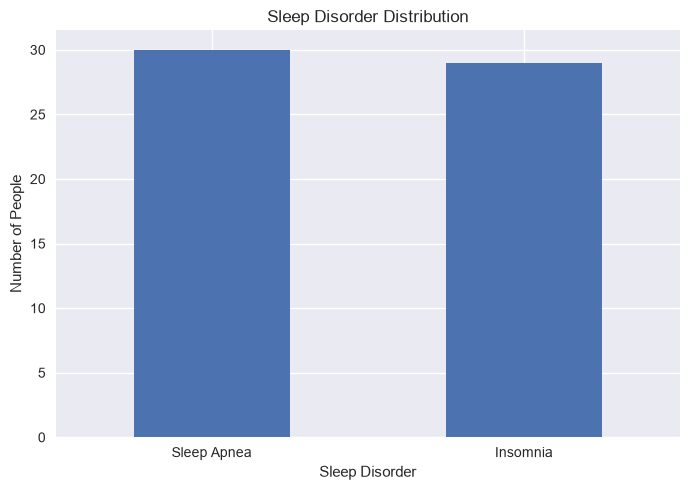

In [41]:

count = df_clean["Sleep Disorder"].value_counts()
percent = df_clean["Sleep Disorder"].value_counts(normalize=True) * 100

result = pd.DataFrame({
    "People": count,
    "Percent": percent.round(1)
})

print(result)

count.plot(kind="bar", figsize=(7, 5))
plt.title("Sleep Disorder Distribution")
plt.xlabel("Sleep Disorder")
plt.ylabel("Number of People")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



**INSIGHT**:
After removing repeated records:
None = 55.3%
Sleep Apnea = 22.7%
Insomnia = 22.0%
So "None" is the largest group in this dataset.


- -----
STEP 9: SLEEP DURATION AND SLEEP QUALITY
------------------------------------------------
WHY:
We want to know whether people in different disorder groups
have different average sleep duration and sleep quality.


                Sleep Duration  Quality of Sleep
Sleep Disorder                                  
Insomnia                  6.68              6.52
Sleep Apnea               6.94              6.87


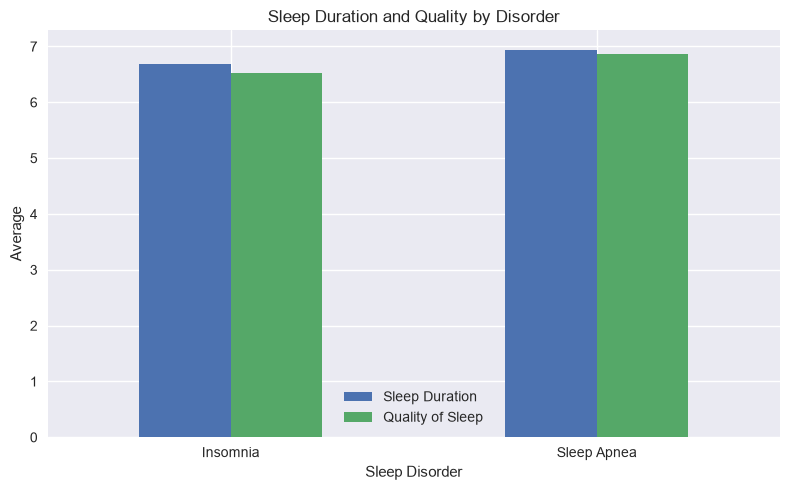

In [42]:

sleep_result = (
    df_clean.groupby("Sleep Disorder")
    [["Sleep Duration", "Quality of Sleep"]]
    .mean()
    .round(2)
)

print(sleep_result)

sleep_result.plot(kind="bar", figsize=(8, 5))
plt.title("Sleep Duration and Quality by Disorder")
plt.xlabel("Sleep Disorder")
plt.ylabel("Average")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



**INSIGHT**:
The "None" group has the highest average sleep quality (7.52).
Insomnia has the lowest average sleep duration (6.68 hours)
and lowest average sleep quality (6.52).


- -----
STEP 10: STRESS AND ACTIVITY
------------------------------------------------
WHY:
Stress and physical activity may be related to sleep.
We compare the average values for each disorder group.


In [1]:

lifestyle = (
    df_clean.groupby("Sleep Disorder")
    [["Stress Level", "Physical Activity Level", "Daily Steps"]]
    .mean()
    .round(3)
)

print(lifestyle)

lifestyle.plot(kind="bar", figsize=(9, 8))
plt.title("Lifestyle Measures by Sleep Disorder")
plt.xlabel("Sleep Disorder")
plt.ylabel("Average")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



NameError: name 'df_clean' is not defined

**INSIGHT**:
Insomnia has the highest average stress level (6.03).
The "None" group has lower average stress (5.18).
This shows a pattern in this dataset, but it does NOT prove
that stress causes insomnia.


- -----
STEP 11: WHICH JOB HAS MORE OF EACH DISORDER?
------------------------------------------------
WHY:
Different jobs have different numbers of people.
So we use percentages inside each job instead of raw counts.
Example:
If a job has 10 people and another has 100 people,
comparing only the number of cases would not be fair.


Sleep Disorder     Insomnia  Sleep Apnea
Occupation                              
Accountant            100.0          0.0
Doctor                 40.0         60.0
Engineer               80.0         20.0
Lawyer                 40.0         60.0
Nurse                  15.0         85.0
Salesperson            75.0         25.0
Scientist               0.0        100.0
Software Engineer     100.0          0.0
Teacher                72.7         27.3


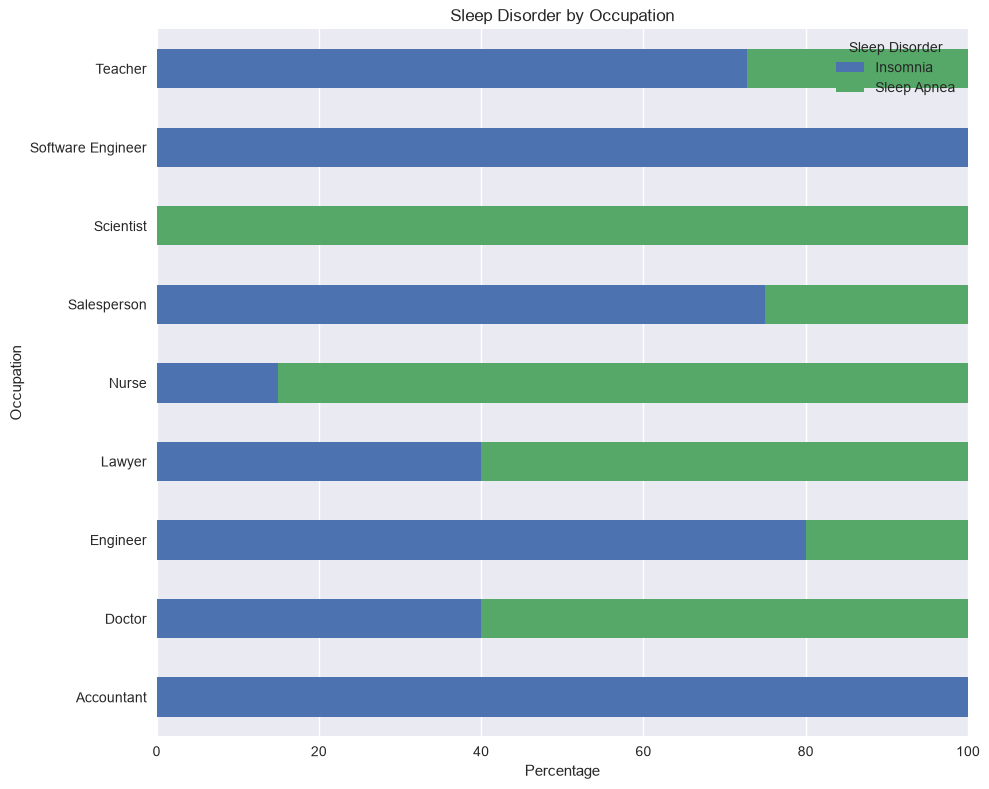

In [44]:

job_result = pd.crosstab(
    df_clean["Occupation"],
    df_clean["Sleep Disorder"],
    normalize="index"
) * 100

print(job_result.round(1))

job_result.plot(kind="barh", stacked=True, figsize=(10, 8))
plt.title("Sleep Disorder by Occupation")
plt.xlabel("Percentage")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()



**INSIGHT**:
In this cleaned dataset:
Nurse has a high Sleep Apnea percentage (58.6%).
Teacher has a high Insomnia percentage (53.3%).
Salesperson also has a high Insomnia percentage (60.0%).
Important:
These are patterns in this dataset.
They do not prove that a job causes a disorder.


- -----
STEP 12: BMI AND SLEEP DISORDER
------------------------------------------------
WHY:
We want to compare sleep disorders inside each BMI category.
Again, percentages are easier to compare than raw counts.


Sleep Disorder  Insomnia  Sleep Apnea
BMI Category                         
Normal              53.3         46.7
Obese               42.9         57.1
Overweight          48.6         51.4


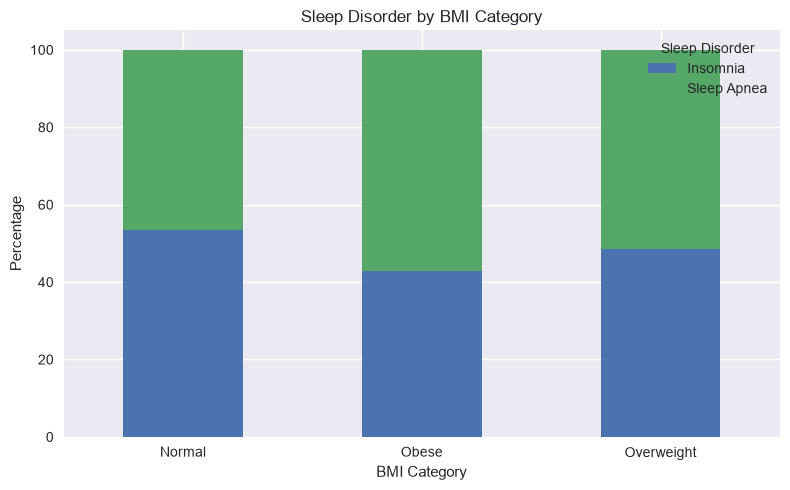

In [45]:

bmi_result = pd.crosstab(
    df_clean["BMI Category"],
    df_clean["Sleep Disorder"],
    normalize="index"
) * 100

print(bmi_result.round(1))

bmi_result.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Sleep Disorder by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



**INSIGHT**:
In this dataset, the Obese group has 57.1% Sleep Apnea
and 42.9% Insomnia.
The Normal group has 79.5% with no disorder.
This is an association seen in the dataset, not proof of cause.


- -----
STEP 13: GENDER AND SLEEP DISORDER
------------------------------------------------
WHY:
We check whether the percentage of disorders is different
between males and females.


Sleep Disorder  Insomnia  Sleep Apnea
Gender                               
Female              38.2         61.8
Male                64.0         36.0


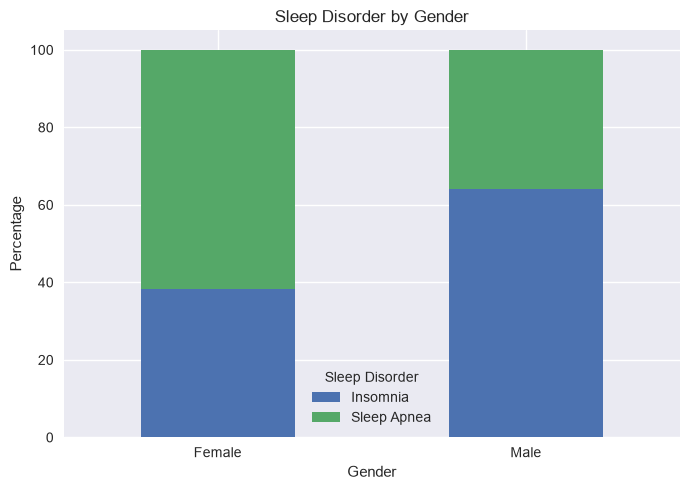

In [46]:

gender_result = pd.crosstab(
    df_clean["Gender"],
    df_clean["Sleep Disorder"],
    normalize="index"
) * 100

print(gender_result.round(1))

gender_result.plot(kind="bar", stacked=True, figsize=(7, 5))
plt.title("Sleep Disorder by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



**INSIGHT**:
Female: 32.3% Sleep Apnea
Male:   13.4% Sleep Apnea
The dataset shows a difference between the two groups.
But we should not say gender CAUSES Sleep Apnea.


- -----
STEP 14: AGE GROUP
------------------------------------------------
WHY:
Age is a number. Groups make it easier to explain in a chart.


Sleep Disorder  Insomnia  Sleep Apnea
Age Group                            
18-29               50.0         50.0
30-39               42.9         57.1
40-49               66.7         33.3
50+                 26.7         73.3


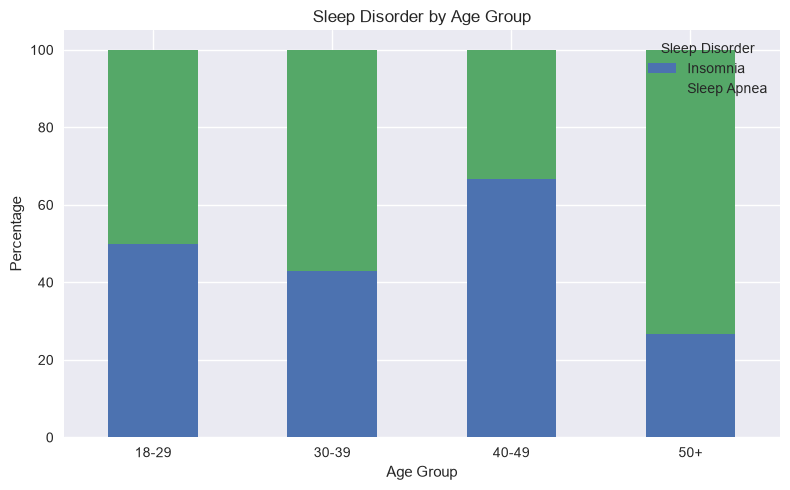

In [47]:

df_clean["Age Group"] = pd.cut(
    df_clean["Age"],
    bins=[0, 29, 39, 49, 100],
    labels=["18-29", "30-39", "40-49", "50+"]
)

age_result = pd.crosstab(
    df_clean["Age Group"],
    df_clean["Sleep Disorder"],
    normalize="index"
) * 100

print(age_result.round(1))

age_result.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Sleep Disorder by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



**INSIGHT**:
The 50+ group has 37.9% Sleep Apnea.
The 40-49 group has 40.0% Insomnia.
These are useful patterns for our dataset.


- -----
STEP 15: STRESS VS SLEEP QUALITY
------------------------------------------------
WHY:
We want to check whether higher stress tends to appear
with lower sleep quality.
Correlation:
- close to -1 = strong negative relationship
- close to 0  = little linear relationship
- close to +1 = strong positive relationship


Correlation: -0.884


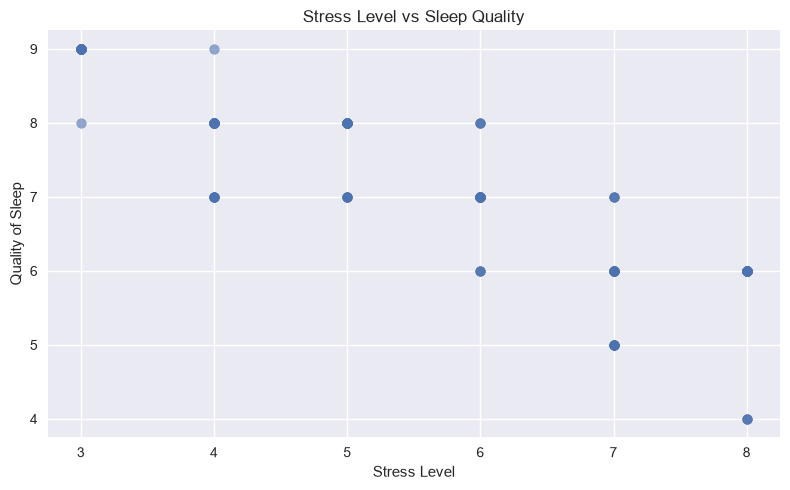

In [48]:

correlation = df_clean["Stress Level"].corr(df_clean["Quality of Sleep"])


print("Correlation:", round(correlation, 3))

plt.figure(figsize=(8, 5))
plt.scatter(
    df_clean["Stress Level"],
    df_clean["Quality of Sleep"],
    alpha=0.6
)
plt.title("Stress Level vs Sleep Quality")
plt.xlabel("Stress Level")
plt.ylabel("Quality of Sleep")
plt.tight_layout()
plt.show()



**INSIGHT**:
Correlation = -0.884.
This is a strong negative relationship in this dataset:
as stress level increases, sleep quality tends to decrease.
IMPORTANT:
Correlation shows a relationship, not proof that one thing causes another.


- -----
STEP 16: HEART RATE AND BLOOD PRESSURE
------------------------------------------------
WHY:
We compare average health measurements between disorder groups.
Note: Using 'Higher_BP' and 'Lower_BP' to match Step 5.


                Heart Rate  Higher_BP  Lower_BP
Sleep Disorder                                 
Insomnia             72.21     131.72     86.41
Sleep Apnea          74.27     134.87     90.00


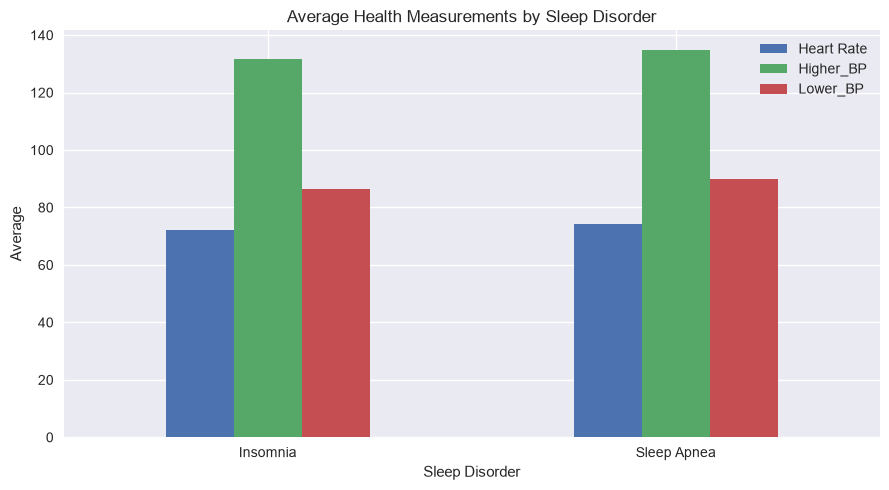

In [49]:

health = (
    df_clean.groupby("Sleep Disorder")
    [["Heart Rate", "Higher_BP", "Lower_BP"]]
    .mean()
    .round(2)
)

print(health)

health.plot(kind="bar", figsize=(9, 5))
plt.title("Average Health Measurements by Sleep Disorder")
plt.xlabel("Sleep Disorder")
plt.ylabel("Average")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



**INSIGHT**:
Sleep Apnea has the highest average Heart Rate (74.27)
and highest average Higher_BP (134.87) in this cleaned dataset.
This is a dataset pattern, not a medical diagnosis.


- ------
# FINAL INSIGHTS
- ------ 

The dataset originally had 374 rows, but repeated records
reduced the analysis to 132 unique records.

The largest group is people with no recorded sleep disorder.

Insomnia has the lowest average sleep duration and sleep quality
among the three sleep-disorder categories.

Insomnia has the highest average stress level in this dataset.

Nurses have a high percentage of Sleep Apnea, while Teachers
and Salespeople have high percentages of Insomnia.

The Obese group has a high percentage of Sleep Apnea and Insomnia.

Female participants have a higher Sleep Apnea percentage than
male participants in this cleaned dataset.

Stress and sleep quality have a strong negative correlation
(-0.884), meaning higher stress tends to appear with lower
sleep quality in these records.

These findings describe patterns in this dataset.
They do not prove that a job, BMI, gender, age, or stress
directly causes a sleep disorder.

PROJECT COMPLETE

______